# Screening for Postpartum Anxiety Symptoms: A Leakage-Aware Comparison of Machine-Learning Models

**Data:** the Kaggle *PostPartum Depression* survey (1,503 responses, 9 questions + the item *Feeling anxious*).
**Task:** predict whether a respondent answers **Yes** to *Feeling anxious* from the other eight symptom items and age band.
**Important:** the target is one self-reported item, not a clinical diagnosis, and the questions describe current symptoms, so this is *symptom screening*, not early prediction.

**Workflow:** 1 Setup, 2 Load, 3 Data quality, 4 Prepare, 5 Split, 6 Candidate models, 7 Compare with cross-validation, 8 Select and tune, 9 Final test, 10 Calibration and risk tiers, 11 Explanation, 12 Why we split by pattern, 13 Conclusions.

## Step 1 — Setup

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.stats import loguniform

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, balanced_accuracy_score,
                             matthews_corrcoef, confusion_matrix, RocCurveDisplay)
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, RandomizedSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.naive_bayes import BernoulliNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
N_SPLITS, N_REPEATS = 5, 3          # repeated cross-validation on the training data

## Step 2 — Load the data

In [2]:
raw = pd.read_csv("post natal data.csv")
print(raw.shape)
raw.head()

(1503, 11)


,Timestamp,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling anxious,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,6/14/2022 20:02,35-40,Yes,Yes,Two or more days a week,Yes,Yes,Yes,No,Yes,Yes
1,6/14/2022 20:03,40-45,Yes,No,No,Yes,Yes,No,Yes,Yes,No
2,6/14/2022 20:04,35-40,Yes,No,Yes,Yes,Yes,Yes,No,Sometimes,No
3,6/14/2022 20:05,35-40,Yes,Yes,Yes,Yes,No,Yes,Maybe,No,No
4,6/14/2022 20:06,40-45,Yes,No,Two or more days a week,Yes,No,Yes,No,Yes,No


## Step 3 — Check data quality

Before modelling we check missing values, repeated answer patterns, and how consistent the label is within a pattern.
Repeated rows matter because if the same answers appear in both the training and test data, a model can look accurate just by memorising them.

In [3]:
TARGET = "Feeling anxious"
FEATURES = [c for c in raw.columns if c not in ("Timestamp", TARGET)]

X_raw = raw[FEATURES].astype(object)
y_raw = (raw[TARGET] == "Yes").astype(int).to_numpy()

pattern = X_raw.fillna("<missing>").astype(str).agg("|".join, axis=1)       # one string per answer pattern
pattern_id = pd.factorize(pattern)[0]
is_repeat = pd.Series(pattern + "|" + pd.Series(y_raw).astype(str)).duplicated().to_numpy()

by_pattern = pd.DataFrame({"p": pattern_id, "y": y_raw}).groupby("p")["y"].agg(["mean", "count"])
conflict = by_pattern["mean"].between(0, 1, inclusive="neither")

print(f"Rows: {len(raw)} | missing cells: {int(X_raw.isna().sum().sum())} (all in 3 columns)")
print(f"Distinct timestamps: {raw['Timestamp'].nunique()} (rows per timestamp up to {raw['Timestamp'].value_counts().max()})")
print(f"Distinct answer patterns (with label): {(~is_repeat).sum()} -> {is_repeat.sum()} rows ({is_repeat.mean():.0%}) repeat an earlier row")
print(f"Patterns that appear with BOTH labels: {conflict.sum()} of {len(by_pattern)} ({conflict.mean():.0%})")
print(f"Share answering 'Feeling anxious = Yes': raw {y_raw.mean():.1%} | repeats removed {y_raw[~is_repeat].mean():.1%}")

Rows: 1503 | missing cells: 27 (all in 3 columns)
Distinct timestamps: 90 (rows per timestamp up to 51)
Distinct answer patterns (with label): 326 -> 1177 rows (78%) repeat an earlier row
Patterns that appear with BOTH labels: 0 of 326 (0%)
Share answering 'Feeling anxious = Yes': raw 65.2% | repeats removed 58.0%


**What this means.** About four in five rows repeat an earlier answer pattern and many rows share the same minute-level timestamp. The origin of the data is undocumented, so we cannot tell whether these are real independent respondents or copied rows.
We therefore take the cautious route: the **main analysis uses each distinct response once** (Step 4), and Step 12 measures how much repeated rows would have inflated the results.

## Step 4 — Prepare the analysis data

* The target becomes 0/1 explicitly (Yes = 1).
* Each distinct response is kept once (repeats removed).
* Each answer pattern gets a *group id*; later splits keep identical patterns together.
* Missing answers are filled and answers are one-hot encoded **inside the model pipeline**, so these steps are learned from training data only.

In [4]:
keep = ~is_repeat
X = X_raw[keep].reset_index(drop=True)
y = y_raw[keep]
groups = pattern_id[keep]

def make_preprocessor():
    return Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

print(f"Analysis set: {len(y)} responses, {y.sum()} anxious ({y.mean():.1%}), {len(set(groups))} answer patterns")

Analysis set: 326 responses, 189 anxious (58.0%), 326 answer patterns


## Step 5 — Hold out a test set

20 % of the data is locked away as the **test set** and used once, at the end. Everything else (the **training set**) is used for comparing and tuning models.
Splitting is grouped by answer pattern and stratified by the label.

In [5]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, y_train, g_train = X.iloc[train_idx], y[train_idx], groups[train_idx]
X_test,  y_test,  g_test  = X.iloc[test_idx],  y[test_idx],  groups[test_idx]

print(f"Train: {len(y_train)} rows, {y_train.mean():.1%} anxious | Test: {len(y_test)} rows, {y_test.mean():.1%} anxious")
print("Patterns shared between train and test:", len(set(g_train) & set(g_test)))

Train: 260 rows, 58.1% anxious | Test: 66 rows, 57.6% anxious
Patterns shared between train and test: 0


## Step 6 — Candidate models and why each is included

The data are 9 categorical questions and about 260 training rows, so the number of possible answer combinations is small and the signal is probably weak. That favours simple, regularised models; flexible models are included to test whether they add anything.

| Model | Why it is a candidate | Main risk here |
|---|---|---|
| Dummy (always predicts the average) | Floor: any real model must beat it | None |
| Logistic regression | Standard for questionnaires, transparent, well-calibrated, hard to overfit | Cannot capture interactions |
| Naive Bayes | Natural for yes/no items, very fast | Assumes items are independent |
| Decision tree (shallow) | Readable if-then rules | Unstable on small data |
| SVM (RBF) | Used in most published postpartum studies | Opaque, needs calibration |
| Random forest | Strong default; captures interactions, robust | Probabilities are less reliable |
| Gradient boosting | Often best on tabular data | Overfits small samples if not limited |
| Soft-voting ensemble | Averages LR + forest + boosting; tests whether combining helps | Gains need diverse errors |
| Stacking ensemble | A logistic model learns how to weight the members | Meta-model can overfit |

Neural networks are left out: with this little data and a finite set of answer combinations they add instability, not accuracy.

In [6]:
def pipe(model):
    return Pipeline([("prep", make_preprocessor()), ("clf", model)])

def members():
    return [("lr", LogisticRegression(C=1.0, max_iter=2000)),
            ("rf", RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=3, random_state=SEED)),
            ("gb", HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=100,
                                                  min_samples_leaf=10, l2_regularization=1.0, random_state=SEED))]

MODELS = {   # listed from simplest to most complex (used as the tie-breaker in Step 8)
    "Dummy":               lambda: DummyClassifier(strategy="prior"),
    "Logistic regression": lambda: pipe(LogisticRegression(C=1.0, max_iter=2000)),
    "Naive Bayes":         lambda: pipe(BernoulliNB()),
    "Decision tree":       lambda: pipe(DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=SEED)),
    "SVM (RBF)":           lambda: pipe(SVC(C=1.0, probability=True, random_state=SEED)),
    "Random forest":       lambda: pipe(RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=3, random_state=SEED)),
    "Gradient boosting":   lambda: pipe(HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=100,
                                                                       min_samples_leaf=10, l2_regularization=1.0, random_state=SEED)),
    "Soft-voting ensemble":lambda: pipe(VotingClassifier(members(), voting="soft")),
    "Stacking ensemble":   lambda: pipe(StackingClassifier(members(), final_estimator=LogisticRegression(max_iter=2000),
                                                           cv=StratifiedKFold(5, shuffle=True, random_state=SEED))),
}
list(MODELS)

['Dummy',
 'Logistic regression',
 'Naive Bayes',
 'Decision tree',
 'SVM (RBF)',
 'Random forest',
 'Gradient boosting',
 'Soft-voting ensemble',
 'Stacking ensemble']

## Step 7 — Compare models with repeated cross-validation (training data only)

Each model is trained and validated on 5 different splits, repeated 3 times (15 runs). We record the score on the part it trained on (**train**) and on the part it did not see (**validation**).
A large gap between them is a sign of overfitting. The main metric is ROC-AUC (1.0 perfect, 0.5 no better than chance).

In [7]:
def repeated_group_folds(y, groups, n_splits=N_SPLITS, n_repeats=N_REPEATS, seed=SEED):
    folds = []
    for r in range(n_repeats):
        sp = StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed + r)
        folds += list(sp.split(np.zeros(len(y)), y, groups))
    return folds

cv_folds = repeated_group_folds(y_train, g_train)
scoring = {"auc": "roc_auc", "brier": "neg_brier_score", "bal_acc": "balanced_accuracy"}

rows, fold_auc = [], {}
for name, make in MODELS.items():
    res = cross_validate(make(), X_train, y_train, cv=cv_folds, scoring=scoring, return_train_score=True)
    fold_auc[name] = res["test_auc"]
    rows.append({"Model": name,
                 "Train AUC": res["train_auc"].mean(),
                 "Validation AUC": res["test_auc"].mean(),
                 "SE": res["test_auc"].std(ddof=1) / np.sqrt(len(cv_folds)),
                 "Gap (train - val)": res["train_auc"].mean() - res["test_auc"].mean(),
                 "Brier": -res["test_brier"].mean(),
                 "Balanced acc.": res["test_bal_acc"].mean()})
cv_table = pd.DataFrame(rows).set_index("Model")
cv_table.round(3)

,Train AUC,Validation AUC,SE,Gap (train - val),Brier,Balanced acc.
Model,,,,,,
Dummy,0.500,0.500,0.000,0.000,0.244,0.500
Logistic regression,0.871,0.805,0.009,0.066,0.182,0.723
Naive Bayes,0.859,0.817,0.007,0.041,0.184,0.723
Decision tree,0.842,0.771,0.015,0.071,0.189,0.721
SVM (RBF),0.978,0.840,0.010,0.138,0.163,0.764
Random forest,0.938,0.842,0.009,0.097,0.170,0.758
Gradient boosting,0.952,0.825,0.011,0.128,0.170,0.748
Soft-voting ensemble,0.929,0.830,0.010,0.099,0.169,0.745
Stacking ensemble,0.937,0.832,0.010,0.104,0.171,0.746


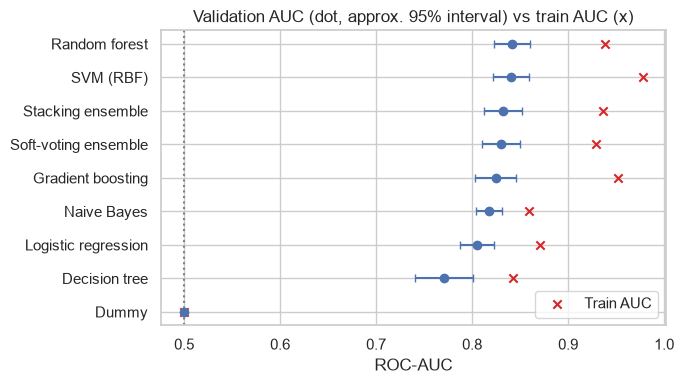

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
order = cv_table["Validation AUC"].sort_values().index
ax.errorbar(cv_table.loc[order, "Validation AUC"], range(len(order)), xerr=1.96 * cv_table.loc[order, "SE"], fmt="o", capsize=3)
ax.scatter(cv_table.loc[order, "Train AUC"], range(len(order)), marker="x", color="tab:red", label="Train AUC")
ax.axvline(0.5, color="grey", ls=":")
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.set_xlabel("ROC-AUC")
ax.set_title("Validation AUC (dot, approx. 95% interval) vs train AUC (x)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## Step 8 — Select the final model and tune it

**Selection rule (fixed using training data only):**
1. Exclude models that memorise the training data: train–validation AUC gap above 0.10.
2. Among the rest, keep every model within one standard error of the best validation AUC.
3. Choose the *simplest* of those (the order in Step 6), so we do not pick a complex model for a difference that is just noise.

Tuning is then checked honestly with **nested cross-validation**: the search is repeated inside each training fold and scored on the fold it never saw. Tuning is kept only if it beats the untuned model that way.

In [9]:
GAP_LIMIT = 0.10
allowed = [m for m in MODELS if m != "Dummy" and cv_table.loc[m, "Gap (train - val)"] <= GAP_LIMIT]
best = cv_table.loc[allowed, "Validation AUC"].idxmax()
cutoff = cv_table.loc[best, "Validation AUC"] - cv_table.loc[best, "SE"]
eligible = [m for m in allowed if cv_table.loc[m, "Validation AUC"] >= cutoff]
selected = eligible[0]                      # MODELS is ordered simplest -> most complex
print("Excluded for overfitting:", [m for m in MODELS if m != "Dummy" and m not in allowed])
print(f"Best remaining: {best} ({cv_table.loc[best, 'Validation AUC']:.3f}) | within 1 SE: {eligible}")
print("Selected model:", selected)

Excluded for overfitting: ['SVM (RBF)', 'Gradient boosting', 'Stacking ensemble']
Best remaining: Random forest (0.842) | within 1 SE: ['Random forest']
Selected model: Random forest


In [10]:
SPACES = {
    "Logistic regression": {"clf__C": loguniform(1e-3, 1e2)},
    "SVM (RBF)": {"clf__C": loguniform(0.1, 50), "clf__gamma": loguniform(1e-3, 1)},
    "Decision tree": {"clf__max_depth": [2, 3, 4, 5], "clf__min_samples_leaf": [5, 10, 20, 30]},
    "Random forest": {"clf__n_estimators": [200, 400], "clf__max_depth": [2, 3, 4, 6],
                      "clf__min_samples_leaf": [1, 3, 5, 10], "clf__max_features": ["sqrt", 0.5]},
    "Gradient boosting": {"clf__learning_rate": loguniform(0.01, 0.2), "clf__max_depth": [2, 3, 4],
                          "clf__max_iter": [50, 100, 200], "clf__min_samples_leaf": [5, 10, 20],
                          "clf__l2_regularization": loguniform(1e-3, 10)},
}
untuned_auc = cv_table.loc[selected, "Validation AUC"]
final_model, validation_auc = MODELS[selected]().fit(X_train, y_train), untuned_auc

if selected in SPACES:
    def new_search():
        return RandomizedSearchCV(MODELS[selected](), SPACES[selected], n_iter=20, scoring="neg_log_loss",
                                  cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED), random_state=SEED, refit=True)
    nested = [roc_auc_score(y_train[te], new_search().fit(X_train.iloc[tr], y_train[tr], groups=g_train[tr])
                            .predict_proba(X_train.iloc[te])[:, 1]) for tr, te in cv_folds]
    nested_auc = float(np.mean(nested))
    print(f"Validation AUC untuned {untuned_auc:.3f} | tuned (nested CV) {nested_auc:.3f}")
    if nested_auc > untuned_auc:
        search = new_search().fit(X_train, y_train, groups=g_train)
        final_model, validation_auc = search.best_estimator_, nested_auc
        print("Tuning kept. Parameters:", search.best_params_)
    else:
        print("Tuning rejected: it does not beat the untuned model; default settings are used.")

Validation AUC untuned 0.842 | tuned (nested CV) 0.853


Tuning kept. Parameters: {'clf__n_estimators': 200, 'clf__min_samples_leaf': 1, 'clf__max_features': 0.5, 'clf__max_depth': 6}


## Step 9 — Final evaluation on the held-out test set

The test set is used **once** with the model chosen above. We report training vs test performance, a dummy baseline for context, and 95 % bootstrap intervals (resampling answer patterns).

In [11]:
def score_all(model, X_, y_, threshold=0.5):
    p = model.predict_proba(X_)[:, 1]; pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_, pred, labels=[0, 1]).ravel()
    return dict(AUC=roc_auc_score(y_, p), PR_AUC=average_precision_score(y_, p), Brier=brier_score_loss(y_, p),
                Accuracy=(tp + tn) / len(y_), Balanced_acc=balanced_accuracy_score(y_, pred),
                Sensitivity=tp / (tp + fn), Specificity=tn / (tn + fp), MCC=matthews_corrcoef(y_, pred)), p

def bootstrap_ci(model, X_, y_, g_, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed); ug = np.unique(g_); idx_by_g = {g: np.where(g_ == g)[0] for g in ug}
    p = model.predict_proba(X_)[:, 1]; out = []
    for _ in range(n_boot):
        idx = np.concatenate([idx_by_g[g] for g in rng.choice(ug, len(ug))])
        if len(np.unique(y_[idx])) == 2:
            out.append([roc_auc_score(y_[idx], p[idx]), brier_score_loss(y_[idx], p[idx]), balanced_accuracy_score(y_[idx], p[idx] >= 0.5)])
    return np.percentile(np.array(out), [2.5, 97.5], axis=0).T          # rows: AUC, Brier, Balanced acc

dummy = MODELS["Dummy"]().fit(X_train, y_train)
train_scores, _ = score_all(final_model, X_train, y_train)
test_scores, p_test = score_all(final_model, X_test, y_test)
dummy_scores, _ = score_all(dummy, X_test, y_test)
ci = bootstrap_ci(final_model, X_test, y_test, g_test)

summary = pd.DataFrame({f"{selected} (train)": train_scores, f"{selected} (test)": test_scores, "Dummy (test)": dummy_scores}).T
print(f"Test AUC 95% CI [{ci[0,0]:.3f}, {ci[0,1]:.3f}] | Brier [{ci[1,0]:.3f}, {ci[1,1]:.3f}] | Balanced acc. [{ci[2,0]:.3f}, {ci[2,1]:.3f}]")
summary.round(3)

Test AUC 95% CI [0.645, 0.874] | Brier [0.140, 0.264] | Balanced acc. [0.600, 0.822]


,AUC,PR_AUC,Brier,Accuracy,Balanced_acc,Sensitivity,Specificity,MCC
Random forest (train),0.997,0.998,0.054,0.954,0.946,0.993,0.899,0.907
Random forest (test),0.768,0.845,0.197,0.727,0.721,0.763,0.679,0.442
Dummy (test),0.500,0.576,0.244,0.576,0.500,1.000,0.000,0.000


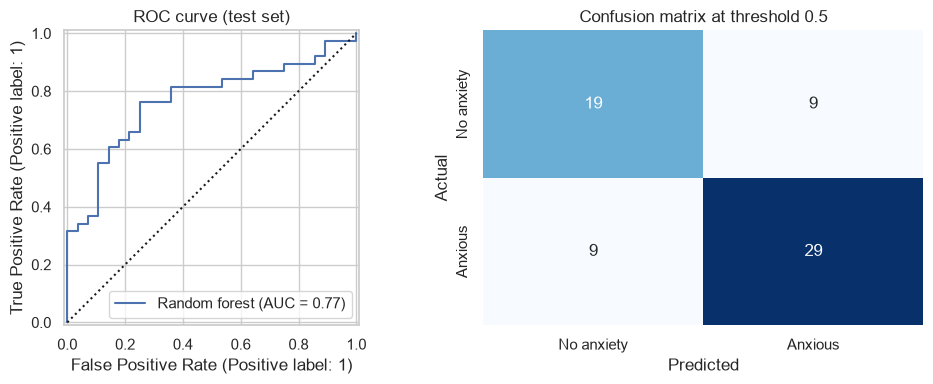

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[0], name=selected); ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_title("ROC curve (test set)")
cm = confusion_matrix(y_test, (p_test >= 0.5).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[1],
            xticklabels=["No anxiety", "Anxious"], yticklabels=["No anxiety", "Anxious"])
ax[1].set(xlabel="Predicted", ylabel="Actual", title="Confusion matrix at threshold 0.5"); plt.tight_layout(); plt.show()

In [13]:
# For reference ONLY (not used to choose anything): how every candidate scores on the test set
ref = []
for name, make in MODELS.items():
    m = make().fit(X_train, y_train); s, _ = score_all(m, X_test, y_test)
    ref.append({"Model": name, "Test AUC": s["AUC"], "Test balanced acc.": s["Balanced_acc"], "Validation AUC (Step 7)": cv_table.loc[name, "Validation AUC"]})
pd.DataFrame(ref).set_index("Model").round(3)

,Test AUC,Test balanced acc.,Validation AUC (Step 7)
Model,,,
Dummy,0.500,0.500,0.500
Logistic regression,0.788,0.703,0.805
Naive Bayes,0.790,0.721,0.817
Decision tree,0.747,0.708,0.771
SVM (RBF),0.787,0.765,0.840
Random forest,0.795,0.778,0.842
Gradient boosting,0.813,0.734,0.825
Soft-voting ensemble,0.800,0.747,0.830
Stacking ensemble,0.806,0.765,0.832


## Step 10 — Calibration and exploratory risk tiers

A screening tool should output probabilities that mean what they say. We calibrate the chosen model (Platt scaling inside cross-validation), then define three tiers using cut-offs found **on the training data only**:
*low* = below the highest cut-off that still catches 90 % of anxious cases; *high* = above the lowest cut-off where at least 80 % are anxious; *medium* = in between.
These tiers are exploratory model outputs, not clinically validated risk categories.

In [14]:
calibrated = Pipeline([("prep", make_preprocessor()),
                       ("clf", CalibratedClassifierCV(clone(final_model.named_steps["clf"]), method="sigmoid",
                                                      cv=StratifiedKFold(5, shuffle=True, random_state=SEED)))])
p_train_oof = cross_val_predict(clone(calibrated), X_train, y_train,
                                cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED), groups=g_train, method="predict_proba")[:, 1]
calibrated.fit(X_train, y_train)
p_cal = calibrated.predict_proba(X_test)[:, 1]

grid = np.unique(np.round(p_train_oof, 3))
t_low = max([t for t in grid if (p_train_oof[y_train == 1] >= t).mean() >= 0.90], default=0.0)
ok = [t for t in grid if (p_train_oof >= t).sum() >= 5 and y_train[p_train_oof >= t].mean() >= 0.80]
t_high = max(t_low, min(ok)) if ok else 1.01
print(f"Cut-offs from training data: low < {t_low:.2f} <= medium < {t_high:.2f} <= high")

tier = np.where(p_cal < t_low, "low", np.where(p_cal < t_high, "medium", "high"))
rows = []
for t in ["low", "medium", "high"]:
    m = tier == t; k, n_ = int(y_test[m].sum()), int(m.sum())
    lo, hi = stats.binomtest(k, n_).proportion_ci(method="wilson") if n_ else (np.nan, np.nan)
    rows.append({"Tier": t, "Test rows": n_, "Observed anxious": f"{k}/{n_}", "Rate (95% CI)": f"{(k/n_ if n_ else np.nan):.2f} [{lo:.2f}, {hi:.2f}]"})
print(f"Brier score on test: uncalibrated {brier_score_loss(y_test, p_test):.3f} | calibrated {brier_score_loss(y_test, p_cal):.3f}")
pd.DataFrame(rows).set_index("Tier")

Cut-offs from training data: low < 0.41 <= medium < 0.48 <= high
Brier score on test: uncalibrated 0.197 | calibrated 0.189


,Test rows,Observed anxious,Rate (95% CI)
Tier,,,
low,24,7/24,"0.29 [0.15, 0.49]"
medium,2,0/2,"0.00 [0.00, 0.66]"
high,40,31/40,"0.78 [0.62, 0.88]"


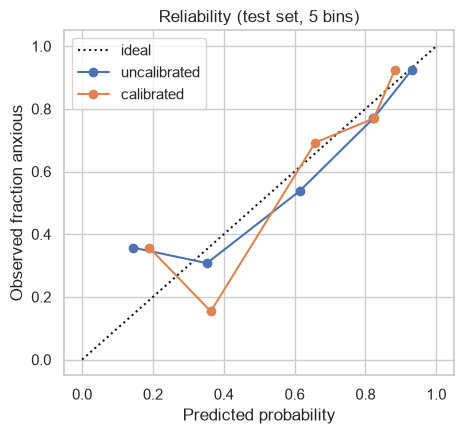

In [15]:
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(4.8, 4.5)); ax.plot([0, 1], [0, 1], "k:", label="ideal")
for label, p_ in [("uncalibrated", p_test), ("calibrated", p_cal)]:
    fr, mp = calibration_curve(y_test, p_, n_bins=5, strategy="quantile"); ax.plot(mp, fr, "o-", label=label)
ax.set(xlabel="Predicted probability", ylabel="Observed fraction anxious", title="Reliability (test set, 5 bins)"); ax.legend()
plt.tight_layout(); plt.show()

## Step 11 — Which questions drive the predictions?

Permutation importance shuffles one question at a time on the test set and measures how much AUC drops. This works for any model.
It shows what the *model relies on*, which is not the same as what *causes* anxiety.

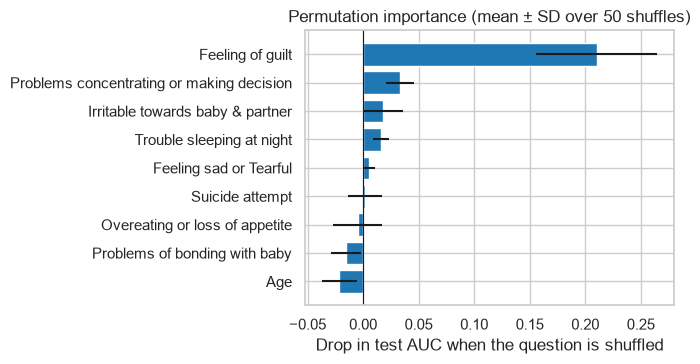

,AUC drop,SD
Feeling of guilt,0.2103,0.0544
Problems concentrating or making decision,0.0334,0.0125
Irritable towards baby & partner,0.0179,0.0180
Trouble sleeping at night,0.0160,0.0072
Feeling sad or Tearful,0.0055,0.0056
Suicide attempt,0.0013,0.0152
Overeating or loss of appetite,-0.0050,0.0222
Problems of bonding with baby,-0.0155,0.0136
Age,-0.0213,0.0158


In [16]:
pi = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=50, random_state=SEED)
imp = pd.DataFrame({"AUC drop": pi.importances_mean, "SD": pi.importances_std}, index=X_test.columns).sort_values("AUC drop")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(imp.index, imp["AUC drop"], xerr=imp["SD"], color="tab:blue"); ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Drop in test AUC when the question is shuffled"); ax.set_title("Permutation importance (mean ± SD over 50 shuffles)")
plt.tight_layout(); plt.show()
imp.sort_values("AUC drop", ascending=False).round(4)

## Step 12 — Why we split by answer pattern (leakage check)

Here the same model type is evaluated on the **raw 1,503 rows** twice: with an ordinary split (identical answer patterns can land in both train and test) and with the grouped split used in this notebook.
A big difference means repeated rows are letting the model memorise answers, which is what could make very high published accuracies on this dataset unreliable.

In [17]:
def cv_auc(model, X_, y_, g_, grouped, repeats=3):
    scores = []
    for r in range(repeats):
        sp = (StratifiedGroupKFold(5, shuffle=True, random_state=SEED + r) if grouped else StratifiedKFold(5, shuffle=True, random_state=SEED + r))
        for tr, te in (sp.split(X_, y_, g_) if grouped else sp.split(X_, y_)):
            m = clone(model).fit(X_.iloc[tr], y_[tr]); scores.append(roc_auc_score(y_[te], m.predict_proba(X_.iloc[te])[:, 1]))
    return np.mean(scores)

leak_models = {"Logistic regression": MODELS["Logistic regression"](), "Random forest (depth 4)": MODELS["Random forest"](),
               "Random forest (unlimited depth)": pipe(RandomForestClassifier(n_estimators=300, random_state=SEED)),
               "Gradient boosting": MODELS["Gradient boosting"]()}
leak = pd.DataFrame({name: {"Ordinary split": cv_auc(m, X_raw, y_raw, pattern_id, False), "Grouped split": cv_auc(m, X_raw, y_raw, pattern_id, True)}
                     for name, m in leak_models.items()}).T
leak["Inflation"] = leak["Ordinary split"] - leak["Grouped split"]
leak.round(3)

,Ordinary split,Grouped split,Inflation
Logistic regression,0.900,0.862,0.038
Random forest (depth 4),0.953,0.911,0.042
Random forest (unlimited depth),0.999,0.923,0.076
Gradient boosting,0.961,0.898,0.063


## Step 13 — Results summary

In [18]:
print(f"Selected model          : {selected}")
print(f"Validation AUC (CV)     : {validation_auc:.3f}   | train AUC (CV): {cv_table.loc[selected, 'Train AUC']:.3f}")
print(f"Train AUC (full train)  : {train_scores['AUC']:.3f}")
print(f"TEST  AUC               : {test_scores['AUC']:.3f}  (95% CI {ci[0,0]:.3f}-{ci[0,1]:.3f}) vs dummy {dummy_scores['AUC']:.3f}")
print(f"TEST  sensitivity/spec. : {test_scores['Sensitivity']:.2f} / {test_scores['Specificity']:.2f} at threshold 0.5")
print(f"Test set size           : {len(y_test)} responses ({int(y_test.sum())} anxious)")
print(f"Ensembles vs best single (validation AUC): voting {cv_table.loc['Soft-voting ensemble','Validation AUC']:.3f}, stacking {cv_table.loc['Stacking ensemble','Validation AUC']:.3f}, best single {cv_table.drop(['Dummy','Soft-voting ensemble','Stacking ensemble'])['Validation AUC'].max():.3f}")
print(f"Average leakage inflation in AUC (ordinary vs grouped split): {leak['Inflation'].mean():+.3f}")

Selected model          : Random forest
Validation AUC (CV)     : 0.853   | train AUC (CV): 0.938
Train AUC (full train)  : 0.997
TEST  AUC               : 0.768  (95% CI 0.645-0.874) vs dummy 0.500
TEST  sensitivity/spec. : 0.76 / 0.68 at threshold 0.5
Test set size           : 66 responses (38 anxious)
Ensembles vs best single (validation AUC): voting 0.830, stacking 0.832, best single 0.842
Average leakage inflation in AUC (ordinary vs grouped split): +0.055


### Interpretation (numbers are from the run saved in this notebook)

**Which model and why.** The Step 8 rule screened out the SVM, gradient boosting and stacking (train AUC far above validation AUC = memorisation), leaving the **random forest** as the only model within one standard error of the best. It suits this problem because it handles interactions between symptoms without assuming a form, is hard to push to extremes with a handful of questions, and needs little tuning. Simple models were close behind (logistic regression 0.81, naive Bayes 0.82 validation AUC vs 0.84 for the forest), so the extra flexibility buys little: with nine coarse questions there is a ceiling on what any model can learn.

**Training vs testing.**

| | AUC |
|---|---|
| Training data (fit and scored on the same rows) | 0.997 |
| Cross-validation on training data (nested, tuned) | 0.853 |
| **Held-out test set (66 responses)** | **0.768** (95 % CI 0.65 to 0.87) |
| Dummy baseline on test | 0.500 |

The model clearly beats chance on unseen data (sensitivity 0.76, specificity 0.68 at a 0.5 cut-off), but it **overfits**: the tuned forest ended up with deep trees that nearly memorise the training rows, and performance drops from training to validation to test. The drop from validation (0.85) to test (0.77) lies within the test set's wide interval, so it is not conclusive, but it suggests the cross-validation figure is optimistic. The reference table in Step 9 shows the untuned models scoring about 0.79 to 0.81 on the same test set, so tuning did not help there. With only 66 test cases, differences of a few AUC points between models are noise; do not rank them from this one split.

**Ensembles.** Soft voting (0.830) and stacking (0.832) did not beat the best single model (0.842) in cross-validation. The member models make similar errors, so averaging them adds little here.

**Calibration and tiers.** Calibration lowered the test Brier score slightly (0.197 to 0.189). Exploratory tiers separate cases reasonably (low tier 29 % anxious, high tier 78 %), but the medium tier holds only two test cases, and the tiers are model outputs, not clinical risk categories.

**Important questions.** Shuffling *Feeling of guilt* costs by far the most AUC (about 0.21); other items contribute little and several are near zero or negative, meaning the model gets no reliable signal from them. This describes what the model relies on, not what causes anxiety.

**Leakage.** On the raw 1,503 rows an ordinary split inflates AUC by about 0.04 to 0.08 compared with the grouped split, and an unrestricted forest reaches 0.999 by memorising repeated rows. Very high accuracies reported on this kind of data should be treated with caution unless repeated rows were handled.

**Limits.** One self-reported item is the label (not a diagnosis); the questions describe current symptoms (not early prediction); the data source is undocumented and 78 % of rows repeat; the test set is small; there is no external validation. The results support a methodological conclusion (symptom items give moderate, not high, discrimination, and careful validation matters), not a clinical tool.